In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#绘制气泡图、箱型图需要
import plotly.express as px

# 读取卖家分析结果
BASE_DIR = Path.cwd().parent
file_path = BASE_DIR / "data" / "processed" / "seller_performance.csv"
seller = pd.read_csv(file_path)

# 检查订单量分布
print(seller['delivered_orders'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(2))

count    2970.00
mean       32.93
std       105.41
min         1.00
25%         2.00
50%         7.00
75%        22.00
90%        73.00
95%       133.00
99%       400.48
max      1819.00
Name: delivered_orders, dtype: float64


In [2]:

#根据订单量给卖家分组
bins = [0, 5, 10, 20, 50, 100, float('inf')]

labels = [
    '1-5',
    '6-10',
    '11-20',
    '21-50',
    '51-100',
    '100+'
]

seller['order_group'] = pd.cut(
    seller['delivered_orders'],
    bins=bins,
    labels=labels
)

#卖家分布
order_distribution = (
    seller.groupby('order_group', observed=False)
    .size()
    .reset_index(name='seller_count')
)

#各组别的占比
order_distribution['percentage'] = (
    order_distribution['seller_count']
    / len(seller) * 100
)

print(order_distribution.round(2))

  order_group  seller_count  percentage
0         1-5          1342       45.19
1        6-10           452       15.22
2       11-20           391       13.16
3       21-50           372       12.53
4      51-100           205        6.90
5        100+           208        7.00


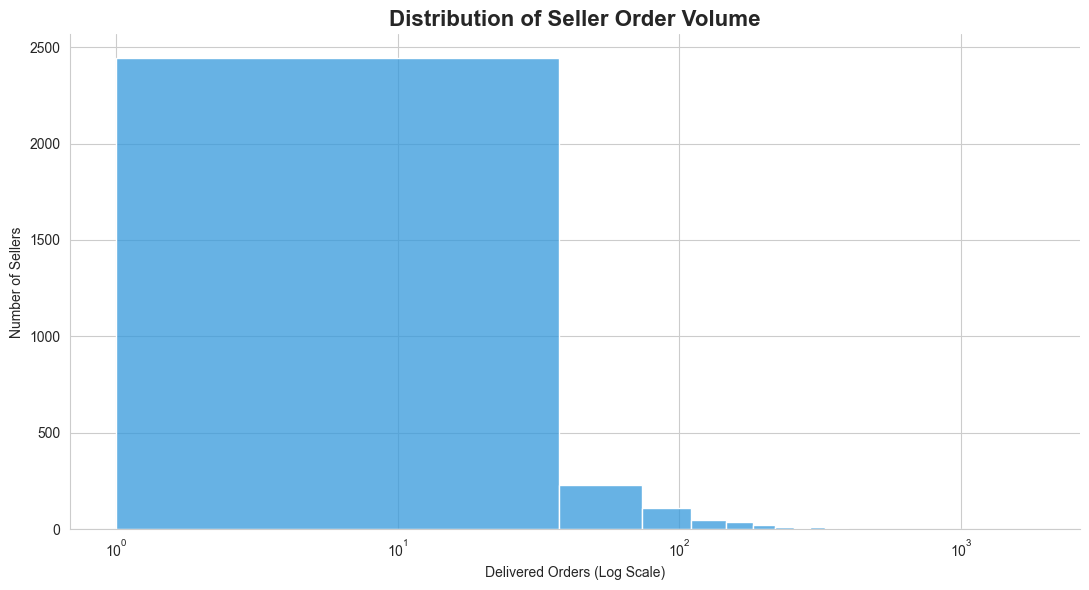

In [3]:
#绘制卖家订单量分布图
plt.figure(figsize=(11, 6))

sns.histplot(
    data=seller,
    x='delivered_orders',
    bins=50,
    color='#3498DB'
)

plt.xscale('log')
#使用对数横轴，因为最大买家有1819笔订单，而中位数只有7笔，使用普通横轴图比较难观察

plt.title(
    'Distribution of Seller Order Volume',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Delivered Orders (Log Scale)')
plt.ylabel('Number of Sellers')

sns.despine()
plt.tight_layout()
plt.show()

In [4]:
#确定卖家评价的可靠性门槛
thresholds = [5, 10, 20, 50, 100]

threshold_result = []

for t in thresholds:

    # 筛选出订单量大于等于当前门槛的卖家
    qualified = seller[seller['delivered_orders'] >= t]


    threshold_result.append({
        'minimum_orders': t,    #门槛是多少
        'qualified_sellers': len(qualified),  #达到门槛的卖家有几个
        'seller_percentage': (
            len(qualified) / len(seller) * 100  #达到门槛的卖家占总数的百分比
        )
    })

threshold_df = pd.DataFrame(threshold_result)

print(threshold_df.round(2))

   minimum_orders  qualified_sellers  seller_percentage
0               5               1766              59.46
1              10               1237              41.65
2              20                804              27.07
3              50                425              14.31
4             100                210               7.07


In [ ]:
#由上述结果分析99%分位数约为400单，但最大值达到1819单，说明头部卖家的业务规模远高于普通卖家.Olist平台的卖家订单分布高度不均衡：大量卖家只有少量已送达订单，而少数卖家承担了相对较大的订单规模
#选择至少20个已送达订单作为后续卖家履约表现比较的初步门槛，20单门槛可以保留804家卖家，占全部卖家的27.07%，有一定的分析规模

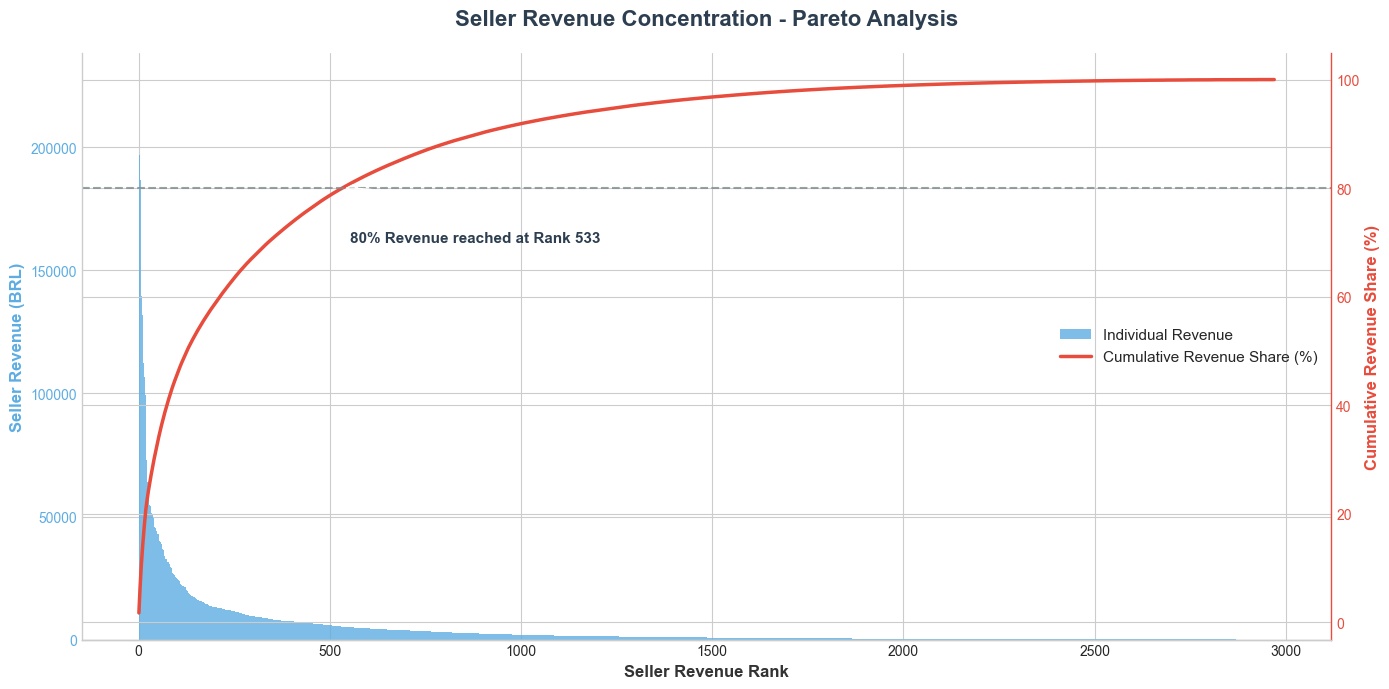

In [15]:
#绘制Pareto图，展示每家卖家的收入分析和累计收入贡献

# 读取数据并排序
file_path = "data/processed/seller_revenue_ranking.csv"
df = pd.read_csv(file_path)
df = df.sort_values("revenue_rank")

# 确保百分比正确
if df["cumulative_revenue_share"].max() <= 1:
    df["cumulative_revenue_share"] *= 100

# ==========================================
# 开始绘图美化
# ==========================================
# 设置图表整体风格为白底浅灰网格，类似 plotly_white
plt.style.use('seaborn-v0_8-whitegrid')

fig, ax1 = plt.subplots(figsize=(14, 7))

# 1. 画柱子 (渐变色蓝色，没有边框线)
# 用 alpha=0.8 增加一点通透感，edgecolor='none' 去掉密密麻麻的黑边
bars = ax1.bar(
    df["revenue_rank"],
    df["total_revenue"],
    width=1.0,
    color='#5DADE2',  # 现代感天蓝色
    alpha=0.8,
    edgecolor='none',
    label="Individual Revenue"
)

ax1.set_xlabel("Seller Revenue Rank", fontsize=12, fontweight='bold', color='#333333')
ax1.set_ylabel("Seller Revenue (BRL)", fontsize=12, fontweight='bold', color='#5DADE2')
ax1.tick_params(axis='y', labelcolor='#5DADE2')

# 2. 画累计折线 (亮橙红色，加粗)
ax2 = ax1.twinx()
line = ax2.plot(
    df["revenue_rank"],
    df["cumulative_revenue_share"],
    color='#E74C3C',  # 抓眼球的橘红色
    linewidth=2.5,
    label="Cumulative Revenue Share (%)"
)

ax2.set_ylabel("Cumulative Revenue Share (%)", fontsize=12, fontweight='bold', color='#E74C3C')
ax2.tick_params(axis='y', labelcolor='#E74C3C')

# 3. 添加 80% 辅助线和文字注释
ax2.axhline(
    80,
    linestyle="--",
    linewidth=1.5,
    color='#7F8C8D',  # 深灰色
    alpha=0.8
)

# 找到第一次达到 80% 的位置，给个标注
hit_80_idx = df[df["cumulative_revenue_share"] >= 80].index[0]
hit_80_rank = df.loc[hit_80_idx, "revenue_rank"]
ax2.annotate(
    f'80% Revenue reached at Rank {int(hit_80_rank)}',
    xy=(hit_80_rank, 80),
    xytext=(hit_80_rank + 20, 70),  # 文字位置稍微往右下偏移
    arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle="arc3,rad=.2"),
    fontsize=11,
    fontweight='bold',
    color='#2C3E50'
)

# 4. 图表美化：边框、标题、图例
ax1.set_title("Seller Revenue Concentration - Pareto Analysis", fontsize=16, fontweight='bold', pad=20, color='#2C3E50')

# 隐藏顶部边框，去掉 ax2 的右侧边框黑线，只保留数据线条
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_color('#E74C3C') # 右轴边框和折线同色
ax1.spines['left'].set_color('#5DADE2')  # 左轴边框和柱子同色
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)


# 合并双轴图例
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right', frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

In [5]:
#卖家绩效分析---研究卖家业务规模与履约质量之间的关系

# 履约表现分析：至少20个已送达订单
seller_delivery = seller[
    seller['delivered_orders'] >= 20
].copy()

# 评价表现分析：至少20条评价
seller_review = seller[
    seller['total_reviews'] >= 20
].copy()

print("履约分析卖家数量：", len(seller_delivery))
print("评价分析卖家数量：", len(seller_review))

履约分析卖家数量： 804
评价分析卖家数量： 801


In [ ]:
#两个筛选口井非常接近，说明达到20个已送达订单的卖家，大多数也有至少20条评论

In [6]:
#查看这801家评价指标卖家是否基本包含在804家履约达标卖家中
delivery_ids = set(seller_delivery['seller_id'])
review_ids = set(seller_review['seller_id'])

print("两组共同卖家：", len(delivery_ids & review_ids))
print("仅履约组：", len(delivery_ids - review_ids))
print("仅评价组：", len(review_ids - delivery_ids))

#结果表示：两组共同卖家有800家，仅履约组有4家，仅评价组有1家1

两组共同卖家： 800
仅履约组： 4
仅评价组： 1


In [9]:
#针对订单数量>=20的804个卖家，绘制卖家履约表现气泡图

# 复制数据，避免修改原始数据
plot_data = seller_delivery.copy()

# 按订单规模分组
plot_data['seller_size'] = pd.cut(
    plot_data['delivered_orders'],
    bins=[0, 50, 100, 500, float('inf')],
    labels=['Small', 'Medium', 'Large', 'Top']
)

# 去除延迟率或收入缺失的记录
plot_data = plot_data.dropna(
    subset=['delayed_rate', 'total_product_revenue']
)

fig = px.scatter(
    plot_data,
    x='delivered_orders',
    y='delayed_rate',
    size='total_product_revenue',
    color='seller_size',
    hover_name='seller_id',
    hover_data={
        'seller_city': True,
        'seller_state': True,
        'delivered_orders': True,
        'delayed_rate': ':.2f',  # 修改点 1：去掉百分比格式化，保留两位小数
        'avg_delivery_days': ':.1f',
        'total_product_revenue': ':.2f'
    },
    log_x=True,
    size_max=35,
    opacity=0.7,
    title='Seller Scale vs. Delivery Delay Rate',
    labels={
        'delivered_orders': 'Delivered Orders (Log Scale)',
        'delayed_rate': 'Delivery Delay Rate (%)', # 修改点 2：坐标轴加上 (%) 单位
        'seller_size': 'Seller Size',
        'total_product_revenue': 'Product Revenue (BRL)'
    }
)

# 添加整体卖家延迟率中位数参考线
median_delay = plot_data['delayed_rate'].median()

fig.add_hline(
    y=median_delay,
    line_dash='dash',
    line_color='gray',
    annotation_text=f'Median Delay Rate: {median_delay:.2f}%' # 修改点 3：手动拼接 % 号
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    height=650,
    legend_title='Seller Size'
)

fig.show()

In [10]:
#针对已送达订单>=20的卖家，比较不同规模卖家的履约表现

# 重新定义卖家规模
plot_data['seller_size'] = pd.cut(
    plot_data['delivered_orders'],
    bins=[0, 50, 100, 500, float('inf')],
    labels=['Small', 'Medium', 'Large', 'Top']
)

# 按卖家规模汇总履约表现
seller_size_summary = (
    plot_data.groupby('seller_size', observed=False)
    #observed=False：保证即使某个规模（比如 Top）一个卖家都没有，结果也会保留这一行，显示为 0，而不会直接消失。
    .agg(
        seller_count=('seller_id', 'nunique'),
        avg_orders=('delivered_orders', 'mean'),
        median_orders=('delivered_orders', 'median'),
        avg_delay_rate=('delayed_rate', 'mean'),     #平均延迟率：对各卖家的延迟率直接求平均
        median_delay_rate=('delayed_rate', 'median'),
        avg_delivery_days=('avg_delivery_days', 'mean'),
        median_delivery_days=('avg_delivery_days', 'median'),
        total_orders=('delivered_orders', 'sum'),
        total_delayed=('delayed_orders', 'sum')
    )
    .reset_index()
)

# 计算订单加权延迟率
seller_size_summary['weighted_delay_rate'] = (
    seller_size_summary['total_delayed']
    / seller_size_summary['total_orders'] * 100
)

print(seller_size_summary.round(2))

  seller_size  seller_count  avg_orders  median_orders  avg_delay_rate  \
0       Small           391       32.04           31.0            7.85   
1      Medium           205       71.39           68.0            7.70   
2       Large           183      191.81          160.0            7.55   
3         Top            25      945.72          910.0            8.23   

   median_delay_rate  avg_delivery_days  median_delivery_days  total_orders  \
0               6.52              12.10                 11.72         12527   
1               6.67              12.36                 11.94         14635   
2               6.67              12.27                 12.22         35101   
3               7.63              13.18                 13.30         23643   

   total_delayed  weighted_delay_rate  
0            997                 7.96  
1           1143                 7.81  
2           2741                 7.81  
3           1969                 8.33  


In [ ]:
#由上表：不同规模卖家的延迟率差异其实很小。Top组的履约表现略差。卖家规模并没有呈现明显的线性改善或恶化

In [11]:
#针对已送达订单>=20的卖家，绘制不同规模卖家的延迟率分布

fig = px.box(
    plot_data,
    x='seller_size',
    y='delayed_rate',
    color='seller_size',
    points='outliers',
    category_orders={
        'seller_size': ['Small', 'Medium', 'Large', 'Top']
    },
    title='Delivery Delay Rate Distribution by Seller Size',
    labels={
        'seller_size': 'Seller Size',
        'delayed_rate': 'Delivery Delay Rate (%)'
    }
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    height=550,
    showlegend=False
)

fig.show()

In [ ]:
#由分组箱型图分析可知，Top组的分布更集中，无异常值。Small组的分布较分散，偏离值最多，延迟率波动最大。Top组的平均延迟率高于其他组。

In [12]:
#检验订单量与延迟率的相关性：订单量与延迟率是否存在单调相关关系？----弱正相关，显著
#由于订单量分布高度偏右，且存在极端大卖家，所以先使用Spearman秩相关系数，而不是直接使用Pearsn相关系数
from scipy.stats import spearmanr

corr, p_value = spearmanr(
    plot_data['delivered_orders'],
    plot_data['delayed_rate']
)

print(f"Spearman correlation: {corr:.4f}")
print(f"P-value: {p_value:.6f}")

Spearman correlation: 0.0825
P-value: 0.019351


In [ ]:
#Spearman correlation: 0.082，正相关，相关性很弱。P-value: 0.019351<0.05,有统计证据表明总体单调性不为0.

In [13]:
#检验不同规模组的延迟率是否存在显著差异：四种卖家规模的延迟率分布是否存在差异----未发现显著差异
from scipy.stats import kruskal

# 分别提取四组卖家的延迟率
small = plot_data.loc[
    plot_data['seller_size'] == 'Small',
    'delayed_rate'
].dropna()

medium = plot_data.loc[
    plot_data['seller_size'] == 'Medium',
    'delayed_rate'
].dropna()

large = plot_data.loc[
    plot_data['seller_size'] == 'Large',
    'delayed_rate'
].dropna()

top = plot_data.loc[
    plot_data['seller_size'] == 'Top',
    'delayed_rate'
].dropna()

# Kruskal-Wallis H test
stat, p_value = kruskal(
    small, medium, large, top
)

print(f"H-statistic: {stat:.4f}")
print(f"P-value: {p_value:.6f}")

H-statistic: 4.0851
P-value: 0.252418
